# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [1]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [2]:
df = pd.read_csv('data/aviation_clean.csv', low_memory=False)
sns.set_theme(style='whitegrid', palette='colorblind')
print(df.shape)
df[['Make', 'Make.Model', 'Total.Passengers', 'Fatal.Serious.Frac', 'Destroyed']].head()

(59814, 31)


,Make,Make.Model,Total.Passengers,Fatal.Serious.Frac,Destroyed
0,Cessna,Cessna 182P,4.0,0.0,0
1,Cessna,Cessna 182RG,2.0,0.0,0
2,Cessna,Cessna 182P,1.0,0.0,0
3,Piper,Piper PA-28R-200,2.0,0.0,0
4,Cessna,Cessna 140,2.0,0.0,0


## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [3]:
# Passenger threshold of 20 to separate small and large airplanes
df['Size'] = np.where(df['Total.Passengers'] > 20, 'Large', 'Small')
small = df[df['Size'] == 'Small']
large = df[df['Size'] == 'Large']
print(df['Size'].value_counts())

# Overall reference values for each group
df.groupby('Size')[['Fatal.Serious.Frac', 'Destroyed']].mean()

Size
Small    58441
Large     1373
Name: count, dtype: int64


,Fatal.Serious.Frac,Destroyed
Size,,
Large,0.103071,0.123088
Small,0.275167,0.213206


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

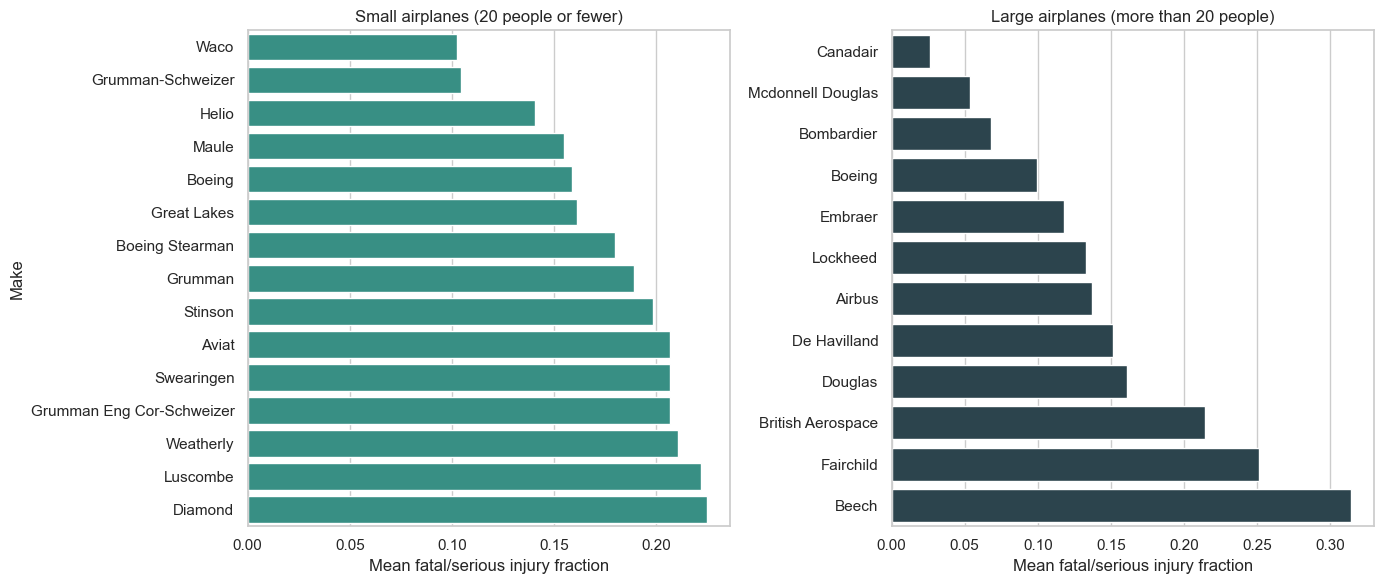

,n,mean_fatal_serious,destroyed_rate
Make,,,
Waco,138,0.103,0.087
Grumman-Schweizer,126,0.104,0.254
Helio,105,0.141,0.124
Maule,570,0.155,0.093
Boeing,571,0.159,0.124
Great Lakes,59,0.161,0.136
Boeing Stearman,50,0.180,0.100
Grumman,1056,0.189,0.245
Stinson,421,0.198,0.133


,n,mean_fatal_serious,destroyed_rate
Make,,,
Canadair,14,0.027,0.071
Mcdonnell Douglas,215,0.053,0.088
Bombardier,66,0.068,0.061
Boeing,731,0.100,0.109
Embraer,63,0.118,0.111
Lockheed,26,0.133,0.192
Airbus,124,0.137,0.153
De Havilland,28,0.152,0.179
Douglas,57,0.161,0.193


In [4]:
def make_profile(data, min_count):
    """Mean injury fraction, destruction rate and count per make, for makes with enough accidents."""
    profile = data.groupby('Make').agg(n=('Make', 'size'),
                                       mean_fatal_serious=('Fatal.Serious.Frac', 'mean'),
                                       destroyed_rate=('Destroyed', 'mean'))
    return profile[profile['n'] >= min_count]

# Minimum sample sizes for robust comparisons: 50 accidents per small make, 10 per large make
# (large airplanes are far rarer in the data)
small_makes = make_profile(small, 50)
large_makes = make_profile(large, 10)

top15_small = small_makes.sort_values('mean_fatal_serious').head(15)
top15_large = large_makes.sort_values('mean_fatal_serious').head(15)

fig, axs = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(x=top15_small['mean_fatal_serious'], y=top15_small.index, ax=axs[0], color='#2a9d8f')
axs[0].set(title='Small airplanes (20 people or fewer)', xlabel='Mean fatal/serious injury fraction', ylabel='Make')
sns.barplot(x=top15_large['mean_fatal_serious'], y=top15_large.index, ax=axs[1], color='#264653')
axs[1].set(title='Large airplanes (more than 20 people)', xlabel='Mean fatal/serious injury fraction', ylabel='')
plt.tight_layout()
plt.show()

display(top15_small.round(3))
display(top15_large.round(3))

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

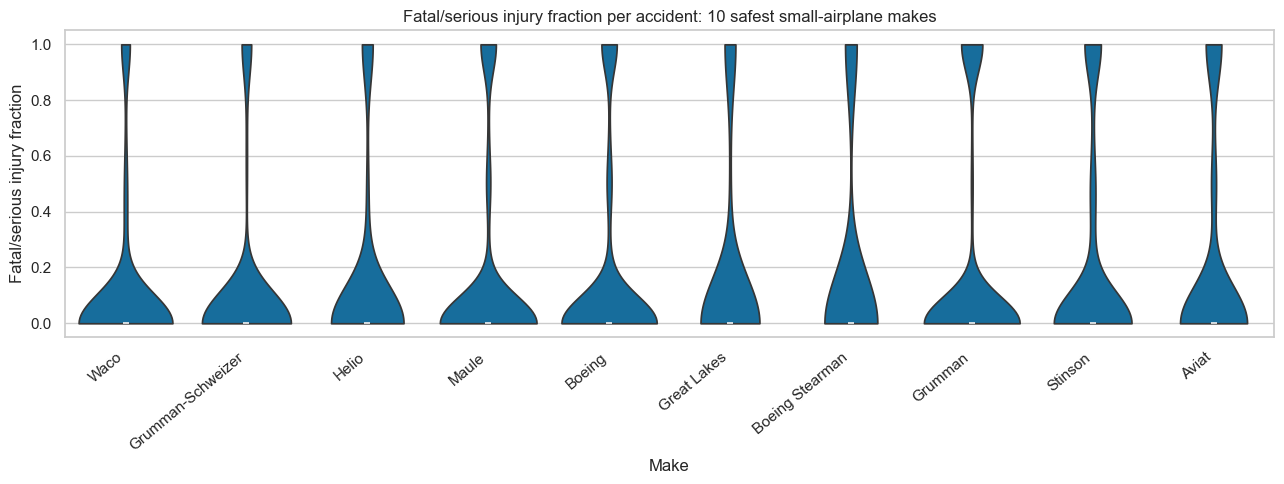

Share of small-airplane accidents with no fatal/serious injury: 0.694


In [5]:
top10_small = top15_small.head(10).index
plt.figure(figsize=(13, 5))
sns.violinplot(data=small[small['Make'].isin(top10_small)], x='Make', y='Fatal.Serious.Frac',
               order=top10_small, cut=0)
plt.title('Fatal/serious injury fraction per accident: 10 safest small-airplane makes')
plt.xlabel('Make')
plt.ylabel('Fatal/serious injury fraction')
plt.xticks(rotation=40, ha='right')
plt.tight_layout()
plt.show()

print('Share of small-airplane accidents with no fatal/serious injury:',
      round((small['Fatal.Serious.Frac'] == 0).mean(), 3))

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

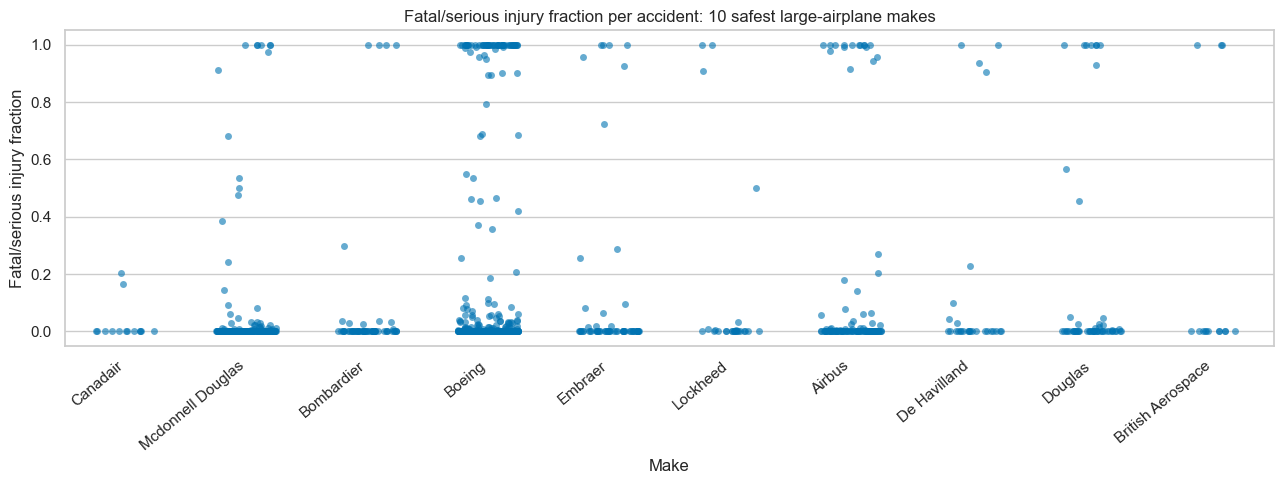

In [6]:
top10_large = top15_large.head(10).index
plt.figure(figsize=(13, 5))
sns.stripplot(data=large[large['Make'].isin(top10_large)], x='Make', y='Fatal.Serious.Frac',
              order=top10_large, jitter=0.25, alpha=0.6)
plt.title('Fatal/serious injury fraction per accident: 10 safest large-airplane makes')
plt.xlabel('Make')
plt.ylabel('Fatal/serious injury fraction')
plt.xticks(rotation=40, ha='right')
plt.tight_layout()
plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

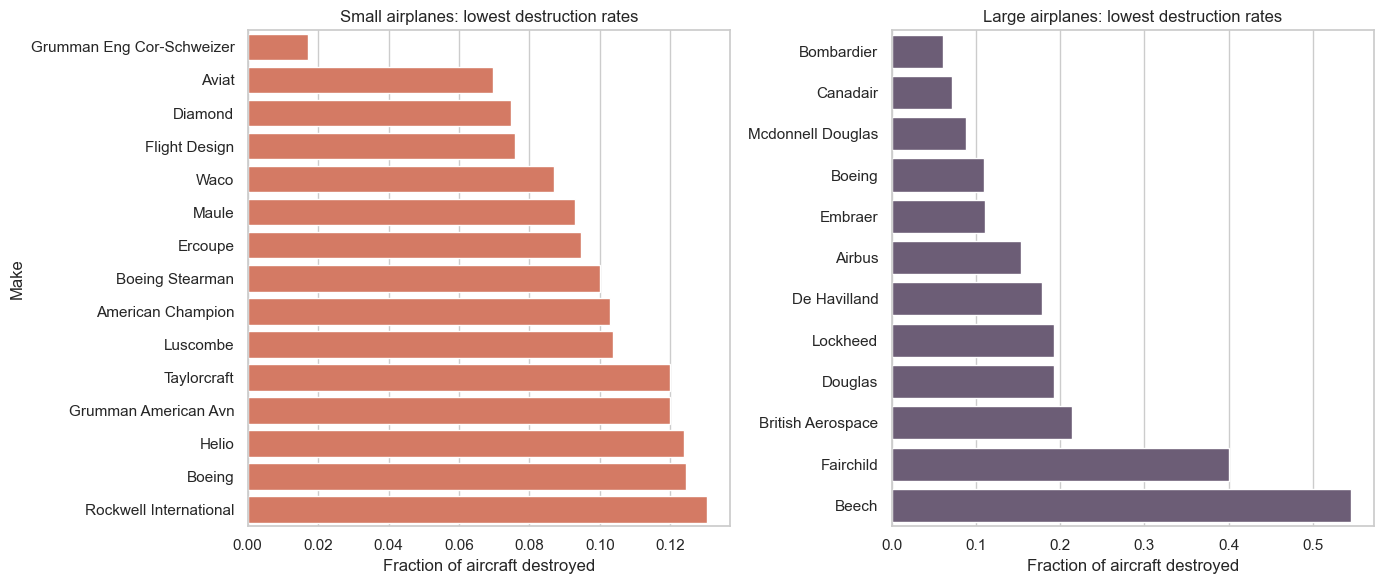

,n,mean_fatal_serious,destroyed_rate
Make,,,
Grumman Eng Cor-Schweizer,58,0.207,0.017
Aviat,230,0.207,0.070
Diamond,174,0.225,0.075
Flight Design,79,0.354,0.076
Waco,138,0.103,0.087
Maule,570,0.155,0.093
Ercoupe,74,0.340,0.095
Boeing Stearman,50,0.180,0.100
American Champion,68,0.294,0.103


,n,mean_fatal_serious,destroyed_rate
Make,,,
Bombardier,66,0.068,0.061
Canadair,14,0.027,0.071
Mcdonnell Douglas,215,0.053,0.088
Boeing,731,0.100,0.109
Embraer,63,0.118,0.111
Airbus,124,0.137,0.153
De Havilland,28,0.152,0.179
Lockheed,26,0.133,0.192
Douglas,57,0.161,0.193


In [7]:
destroyed_small = small_makes.sort_values('destroyed_rate').head(15)
destroyed_large = large_makes.sort_values('destroyed_rate').head(15)

fig, axs = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(x=destroyed_small['destroyed_rate'], y=destroyed_small.index, ax=axs[0], color='#e76f51')
axs[0].set(title='Small airplanes: lowest destruction rates', xlabel='Fraction of aircraft destroyed', ylabel='Make')
sns.barplot(x=destroyed_large['destroyed_rate'], y=destroyed_large.index, ax=axs[1], color='#6d597a')
axs[1].set(title='Large airplanes: lowest destruction rates', xlabel='Fraction of aircraft destroyed', ylabel='')
plt.tight_layout()
plt.show()

display(destroyed_small.round(3))
display(destroyed_large.round(3))

#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

**Discussion: Makes**

*Reference values.* When an accident happens, large airplanes are much less severe than small ones: on average 10.3% of the people on board are seriously or fatally injured (12.3% of aircraft destroyed), versus 27.5% for small airplanes (21.3% destroyed).

*Small airplanes (makes with at least 50 accidents).*
- **Maule** (570 accidents) combines a low injury fraction (15.5%) with a low destruction rate (9.3%), on a large sample: it is our strongest recommendation.
- **Aviat** (230 accidents, 20.7% injured, 7.0% destroyed) and **Diamond** (174 accidents, 22.5% injured, 7.5% destroyed) have among the lowest destruction rates, with injury fractions below the 27.5% average.
- **Waco** (138 accidents, 10.3% injured, 8.7% destroyed) also performs very well on both metrics, on a smaller sample.
- Some makes rank well on one metric only (e.g. Grumman-Schweizer: 10.4% injured but 25.4% destroyed), so both metrics must be considered together.
- Boeing appears among "small" airplanes because the passenger count is only a proxy for size: cargo flights of large jets carry few people, and Boeing Stearman biplanes are counted separately.

*Large airplanes (makes with at least 10 accidents).*
- **McDonnell Douglas** (215 accidents, 5.3% injured, 8.8% destroyed), **Bombardier** (66 accidents, 6.8% injured, lowest destruction rate at 6.1%) and **Boeing** (731 accidents, 10.0% injured, 10.9% destroyed) are the recommended makes.
- Canadair has the lowest injury fraction (2.7%) but only 14 accidents, so the estimate is not robust.

*Distributions.* The violin and strip plots show that the injury fraction is **bimodal**: about 69% of small-airplane accidents have no serious/fatal injury at all (fraction 0), while a minority are catastrophic (fraction close to 1). The mean therefore summarizes "how often an accident turns catastrophic" rather than a typical accident, which is why we always look at the distribution as well as the mean.

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

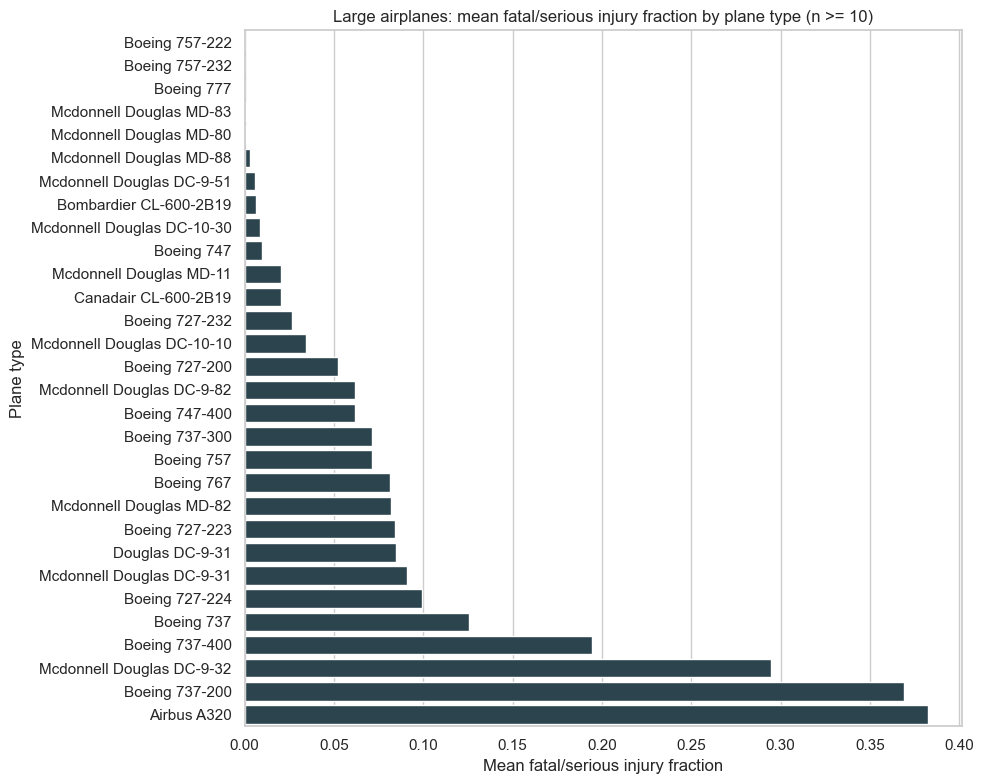

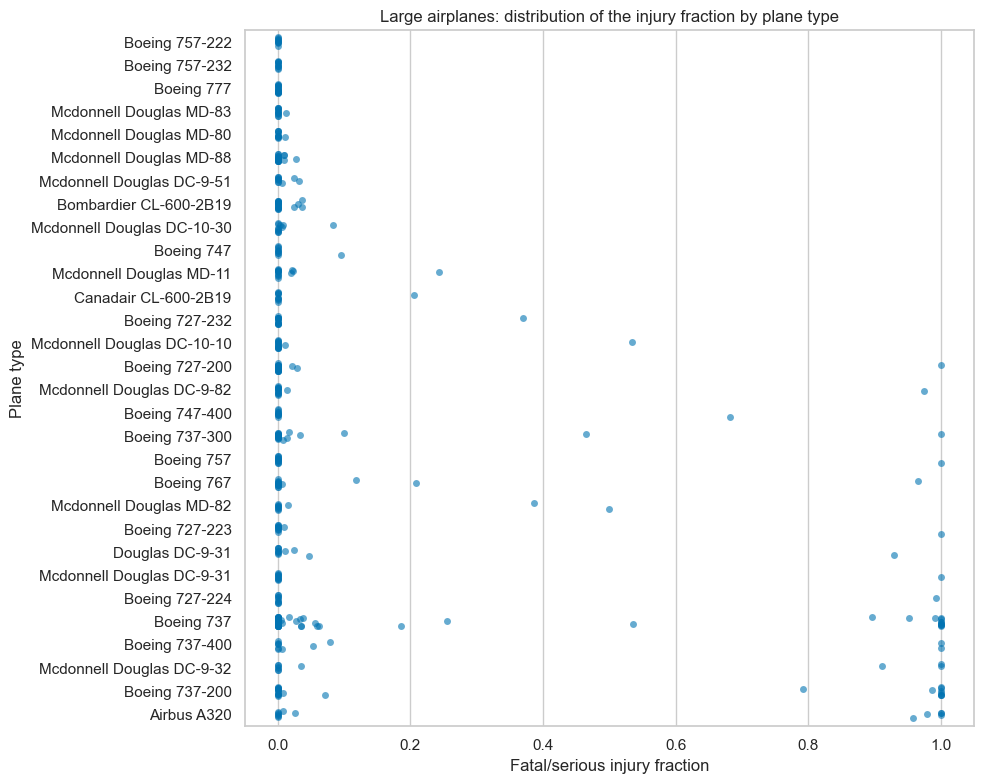

,n,mean_fatal_serious,destroyed_rate
Make.Model,,,
Boeing 757-222,10,0.000,0.000
Boeing 757-232,10,0.000,0.000
Boeing 777,18,0.000,0.056
Mcdonnell Douglas MD-83,13,0.001,0.077
Mcdonnell Douglas MD-80,11,0.001,0.000
Mcdonnell Douglas MD-88,20,0.003,0.000
Mcdonnell Douglas DC-9-51,11,0.006,0.091
Bombardier CL-600-2B19,21,0.006,0.000
Mcdonnell Douglas DC-10-30,12,0.008,0.083


In [8]:
def model_profile(data, min_count=10):
    profile = data.groupby('Make.Model').agg(n=('Make.Model', 'size'),
                                             mean_fatal_serious=('Fatal.Serious.Frac', 'mean'),
                                             destroyed_rate=('Destroyed', 'mean'))
    return profile[profile['n'] >= min_count]

# Large planes: plane types with at least 10 accidents
large_models = model_profile(large).sort_values(['mean_fatal_serious', 'destroyed_rate'])

plt.figure(figsize=(10, 8))
sns.barplot(x=large_models['mean_fatal_serious'], y=large_models.index, color='#264653')
plt.title('Large airplanes: mean fatal/serious injury fraction by plane type (n >= 10)')
plt.xlabel('Mean fatal/serious injury fraction')
plt.ylabel('Plane type')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 8))
sns.stripplot(data=large[large['Make.Model'].isin(large_models.index)], x='Fatal.Serious.Frac',
              y='Make.Model', order=large_models.index, jitter=0.2, alpha=0.6)
plt.title('Large airplanes: distribution of the injury fraction by plane type')
plt.xlabel('Fatal/serious injury fraction')
plt.ylabel('Plane type')
plt.tight_layout()
plt.show()

large_models.round(3)

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

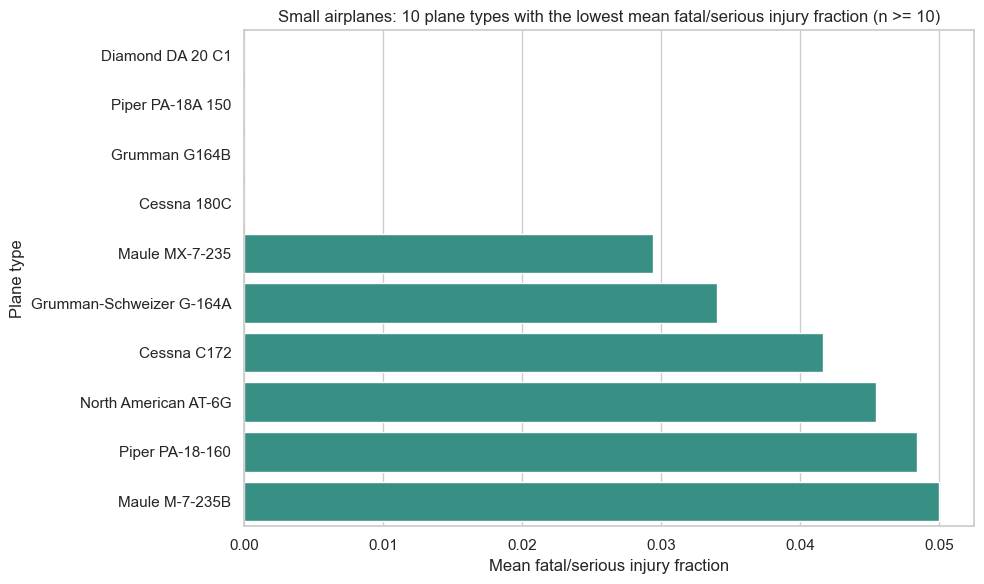

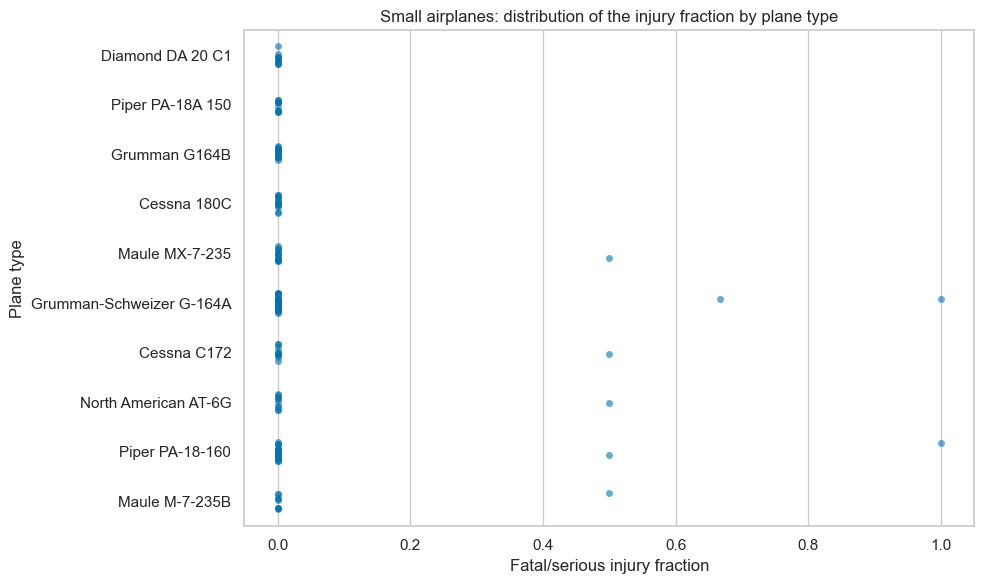

Small plane types with at least 10 accidents: 748


,n,mean_fatal_serious,destroyed_rate
Make.Model,,,
Diamond DA 20 C1,11,0.000,0.000
Piper PA-18A 150,12,0.000,0.000
Grumman G164B,16,0.000,0.062
Cessna 180C,15,0.000,0.067
Maule MX-7-235,17,0.029,0.000
Grumman-Schweizer G-164A,49,0.034,0.163
Cessna C172,12,0.042,0.000
North American AT-6G,11,0.045,0.000
Piper PA-18-160,31,0.048,0.032


In [9]:
# Small planes: plane types with at least 10 accidents, plotted for the 10 lowest mean injury fractions
small_models = model_profile(small).sort_values(['mean_fatal_serious', 'destroyed_rate'])
top10_small_models = small_models.head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top10_small_models['mean_fatal_serious'], y=top10_small_models.index, color='#2a9d8f')
plt.title('Small airplanes: 10 plane types with the lowest mean fatal/serious injury fraction (n >= 10)')
plt.xlabel('Mean fatal/serious injury fraction')
plt.ylabel('Plane type')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
sns.stripplot(data=small[small['Make.Model'].isin(top10_small_models.index)], x='Fatal.Serious.Frac',
              y='Make.Model', order=top10_small_models.index, jitter=0.2, alpha=0.6)
plt.title('Small airplanes: distribution of the injury fraction by plane type')
plt.xlabel('Fatal/serious injury fraction')
plt.ylabel('Plane type')
plt.tight_layout()
plt.show()

print('Small plane types with at least 10 accidents:', len(small_models))
top10_small_models.round(3)

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

**Discussion: Specific airplane types (at least 10 accidents per type)**

*Large airplanes.* Several types show an almost zero fatal/serious injury fraction: **Boeing 777** (18 accidents, 0.0%), the **McDonnell Douglas MD-80 family** (MD-88: 20 accidents, 0.3%; MD-83: 13 accidents, 0.1%), the **Bombardier/Canadair CL-600-2B19 (CRJ)** (21 + 10 accidents, below 2.5%) and the **Boeing 747** (10 accidents, 1.0%). Most of these also have a destruction rate below 10%. The strip plot shows that almost all of their accidents have an injury fraction of 0. Recommended types: Boeing 777, MD-88, CRJ (CL-600-2B19), Boeing 747.

*Small airplanes.* The best types are the **Maule MX-7-235** (17 accidents, 2.9% injured, 0% destroyed), the **Piper PA-18-160 Super Cub** (31 accidents, 4.8% injured, 3.2% destroyed) and the **Grumman-Schweizer G-164A** (49 accidents, 3.4% injured, but 16.3% destroyed: an agricultural aircraft). This is consistent with the make-level results (Maule).

*Caveat.* With 10 to 50 accidents per type, uncertainty remains high: these types should be treated as promising candidates to investigate further rather than definitive conclusions. Types with more accidents (Piper PA-18-160, Grumman-Schweizer G-164A, Boeing 737-300, MD-88) give more reliable estimates.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

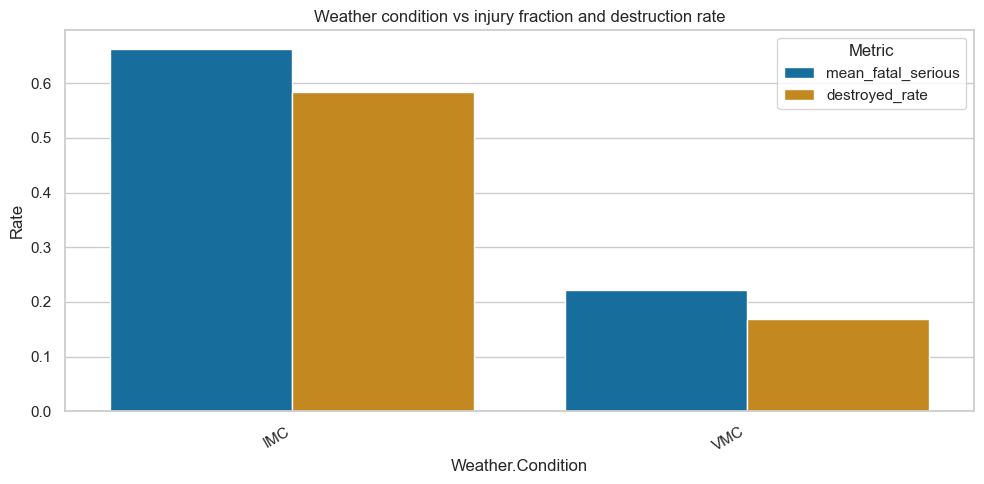

,n,mean_fatal_serious,destroyed_rate
Weather.Condition,,,
IMC,4791,0.663,0.584
VMC,52519,0.222,0.168


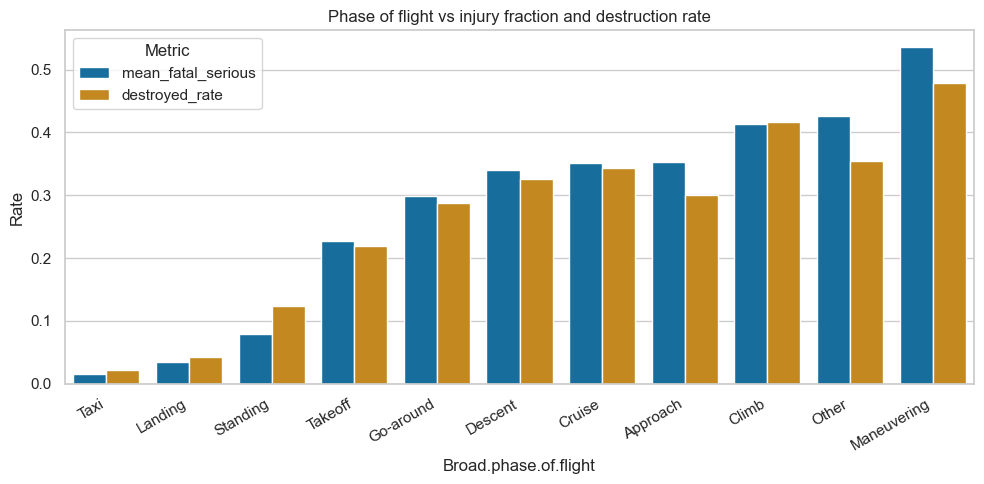

,n,mean_fatal_serious,destroyed_rate
Broad.phase.of.flight,,,
Taxi,1516,0.016,0.022
Landing,11995,0.035,0.043
Standing,517,0.080,0.124
Takeoff,8941,0.227,0.219
Go-around,1171,0.300,0.288
Descent,1262,0.339,0.326
Cruise,7144,0.352,0.343
Approach,4586,0.352,0.300
Climb,1454,0.413,0.417


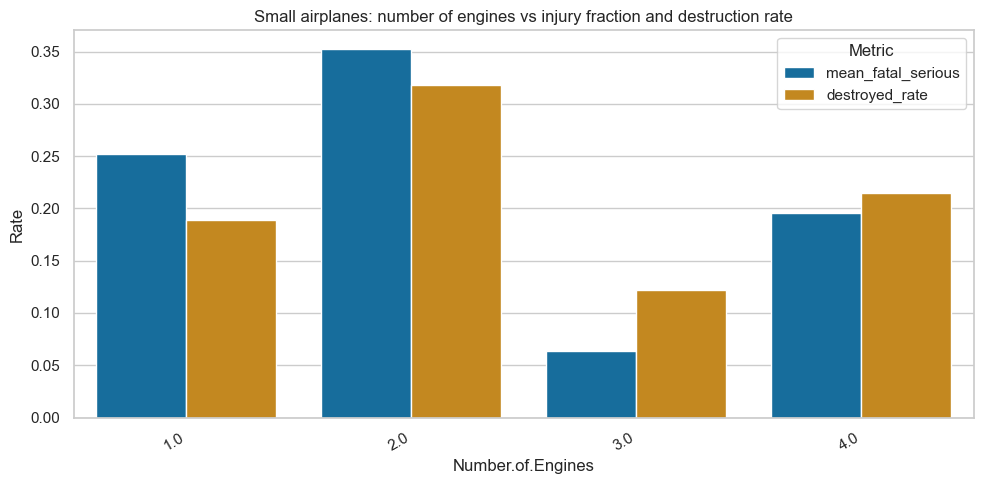

,n,mean_fatal_serious,destroyed_rate
Number.of.Engines,,,
1.0,48716,0.252,0.189
2.0,7291,0.353,0.318
3.0,74,0.064,0.122
4.0,186,0.196,0.215


In [10]:
def factor_profile(data, col, min_count=50):
    profile = data.groupby(col).agg(n=(col, 'size'),
                                    mean_fatal_serious=('Fatal.Serious.Frac', 'mean'),
                                    destroyed_rate=('Destroyed', 'mean'))
    return profile[profile['n'] >= min_count]

def plot_factor(profile, title):
    long = (profile[['mean_fatal_serious', 'destroyed_rate']].reset_index()
            .melt(id_vars=profile.index.name, var_name='Metric', value_name='Rate'))
    plt.figure(figsize=(10, 5))
    sns.barplot(data=long, x=profile.index.name, y='Rate', hue='Metric')
    plt.title(title)
    plt.xticks(rotation=30, ha='right')
    plt.tight_layout()
    plt.show()

# Factor 1: weather condition (VMC = visual conditions, IMC = instrument conditions)
weather = factor_profile(df, 'Weather.Condition')
plot_factor(weather, 'Weather condition vs injury fraction and destruction rate')
display(weather.round(3))

# Factor 2: broad phase of flight
phase = factor_profile(df, 'Broad.phase.of.flight').sort_values('mean_fatal_serious')
plot_factor(phase, 'Phase of flight vs injury fraction and destruction rate')
display(phase.round(3))

# Factor 3: number of engines, within small airplanes only (to limit confounding with airliners)
engines = factor_profile(small, 'Number.of.Engines')
plot_factor(engines, 'Small airplanes: number of engines vs injury fraction and destruction rate')
display(engines.round(3))

**Discussion: Other factors**

*Factor 1: Weather condition.* This is the strongest factor in the data. In instrument meteorological conditions (**IMC**, poor visibility; 4,791 accidents), 66.3% of the people on board are seriously or fatally injured and 58.4% of aircraft are destroyed, versus 22.2% and 16.8% in visual conditions (**VMC**; 52,519 accidents): roughly **three times more severe**. IMC accidents are often controlled flight into terrain or loss of control at speed. Recommendation: the insurer could take pilots' instrument rating and aircraft instrument equipment into account.

*Factor 2: Phase of flight.* Accidents during **taxi** (1.6% injured) and **landing** (3.5%; the most frequent phase with 11,995 accidents) are frequent but rarely severe, because speed and height are low. **Maneuvering** (53.5% injured, 47.8% destroyed: aerobatics, low-altitude or agricultural flying) and **climb** (41.3% injured) are the most dangerous phases. Frequency and severity must therefore be distinguished.

*Factor 3: Number of engines (small airplanes only).* Among small airplanes, twin-engine aircraft (7,291 accidents) have more severe accidents than single-engine ones (48,716 accidents): 35.3% vs 25.2% injured and 31.8% vs 18.9% destroyed. A plausible explanation is that twins fly faster and an engine failure creates asymmetric thrust that is hard to control. The 3- and 4-engine groups are too small (74 and 186 accidents) to conclude.

*Limitations.* The dataset only contains accidents, with no information on the number of flights or flight hours: it measures the **severity of an accident when it happens**, not the **probability** of having one. Exposure data (flight hours per model) would be needed to compare accident rates. Factors may also be confounded (e.g. type of operation, pilot experience), so these relationships are associations, not proven causes.